# Chapter 10: Working with Unlabeled Data – Clustering Analysis

- clustering is to find a natural grouping in data so that items in the 
    same cluster are more similar to each other than to those from different clusters.

### Kmeans Clustering 

- prototype-based clustering. 

- In this case each cluster is defined by a representative member which is either the center or median of the data points. 

-  we do not have any ground-truth category information

- 



In [1]:
import matplotlib.pyplot as plt

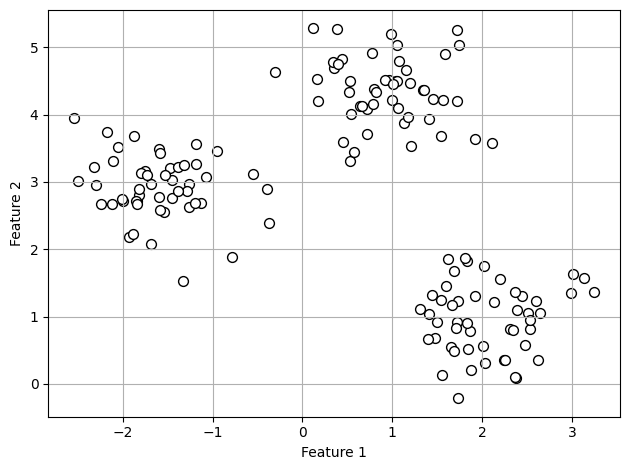

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=150,
                    n_features=2,
                    centers=3,
                    cluster_std=0.5,
                    shuffle=True,
                   random_state=0)

plt.scatter(X[:, 0],
              X[:, 1],
              c='white',
              marker='o',
              edgecolor='black',
              s=50)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid()
plt.tight_layout()
plt.show()

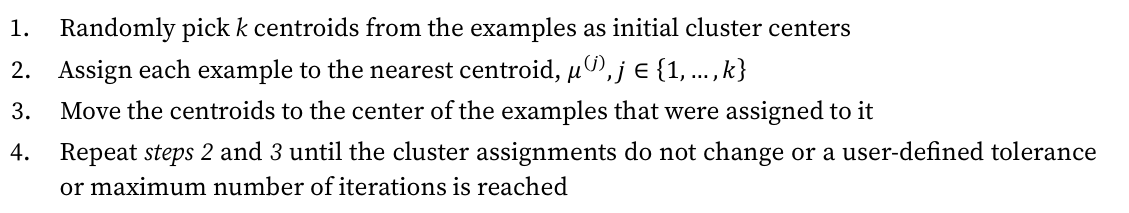

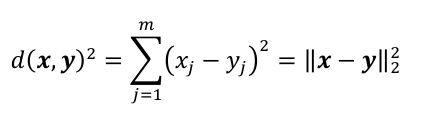

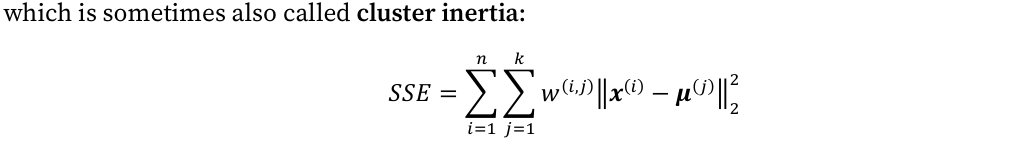

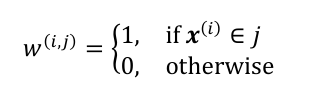

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


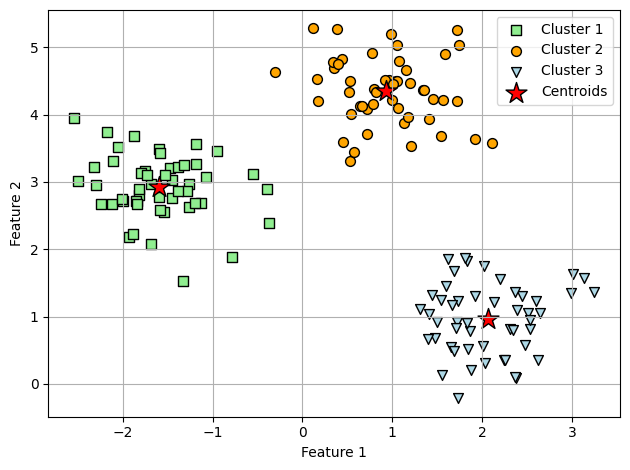

In [7]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3 , init='random' , n_init=10, max_iter = 300 , tol=1e-04 , random_state=0)
y_km = km.fit_predict(X)
plt.scatter(X[y_km == 0, 0],
              X[y_km == 0, 1],
              s=50, c='lightgreen',
             marker='s', edgecolor='black',
             label='Cluster 1')
plt.scatter(X[y_km == 1, 0],
              X[y_km == 1, 1],
              s=50, c='orange',
              marker='o', edgecolor='black',
              label='Cluster 2')
plt.scatter(X[y_km == 2, 0],
              X[y_km == 2, 1],
              s=50, c='lightblue',
              marker='v', edgecolor='black',
              label='Cluster 3')
plt.scatter(km.cluster_centers_[:, 0],
              km.cluster_centers_[:, 1],
             s=250, marker='*',
              c='red', edgecolor='black',
              label='Centroids')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(scatterpoints=1)
plt.grid()
plt.tight_layout()
plt.show()

### k-means++

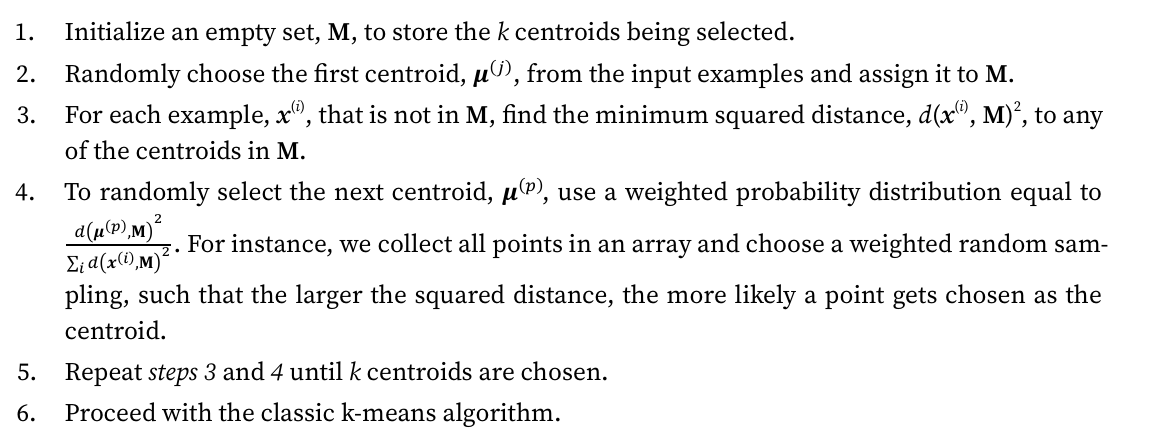

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


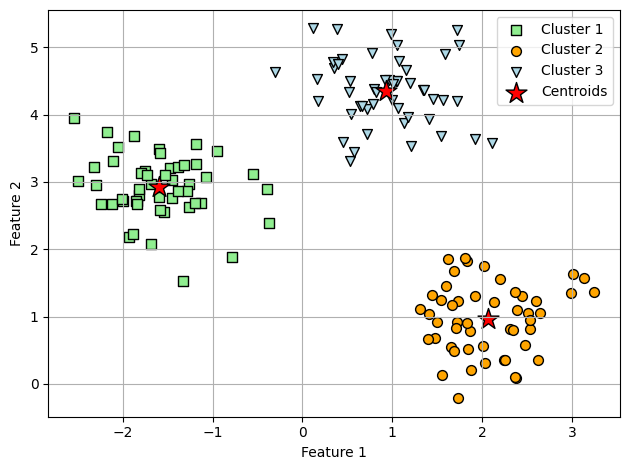

In [8]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3 , init='k-means++' , n_init=10, max_iter = 300 , tol=1e-04 , random_state=0)
y_km = km.fit_predict(X)
plt.scatter(X[y_km == 0, 0],
              X[y_km == 0, 1],
              s=50, c='lightgreen',
             marker='s', edgecolor='black',
             label='Cluster 1')
plt.scatter(X[y_km == 1, 0],
              X[y_km == 1, 1],
              s=50, c='orange',
              marker='o', edgecolor='black',
              label='Cluster 2')
plt.scatter(X[y_km == 2, 0],
              X[y_km == 2, 1],
              s=50, c='lightblue',
              marker='v', edgecolor='black',
              label='Cluster 3')
plt.scatter(km.cluster_centers_[:, 0],
              km.cluster_centers_[:, 1],
             s=250, marker='*',
              c='red', edgecolor='black',
              label='Centroids')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(scatterpoints=1)
plt.grid()
plt.tight_layout()
plt.show()

### Hard versus soft clustering

- Hard Clustering each is assigned to exactly one class 

- Soft Clustering is more spread

- FCM , soft Kmeans clustering . In constract to the normal hard clustering Kmeans. This assigns probability of an example being in each of the cetroids 

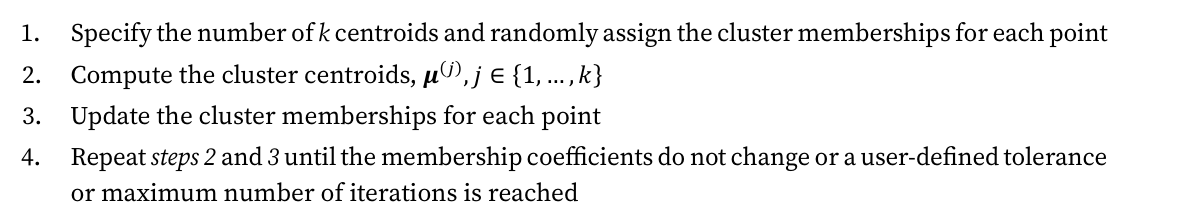

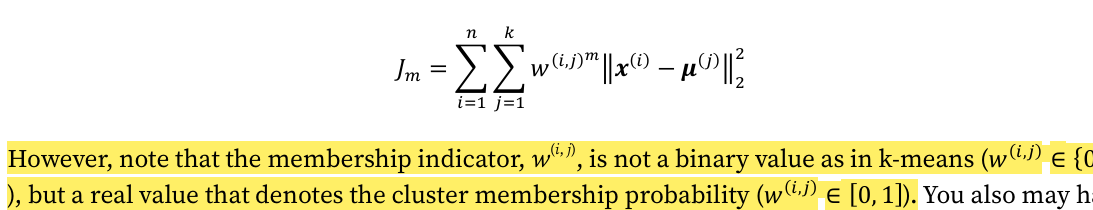

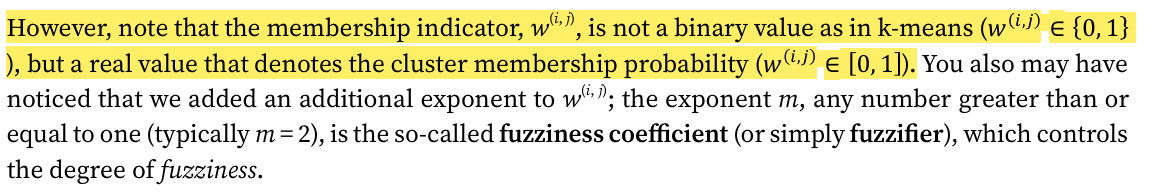

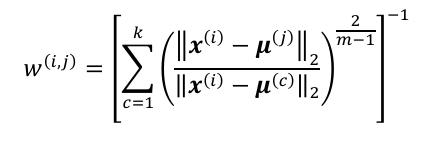

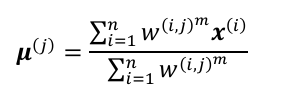

### Using the elbow method to find the optimal number of clusters

- No ground truth in unsupervised learning 

- we need to use intrisic metrices :  within-cluster SSE (distortion) , cluster cohesion, a(i) , cluster separation , 

In [9]:
print(f'Distortion: {km.inertia_:.2f}')

Distortion: 72.48


In [13]:
distortions = []

for i in range(1,11): 
    km = KMeans(n_clusters=i ,
                init='k-means++',
                n_init=10,
                max_iter=300,
                random_state=0)
    km.fit(X)
    distortions.append(km.inertia_)

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

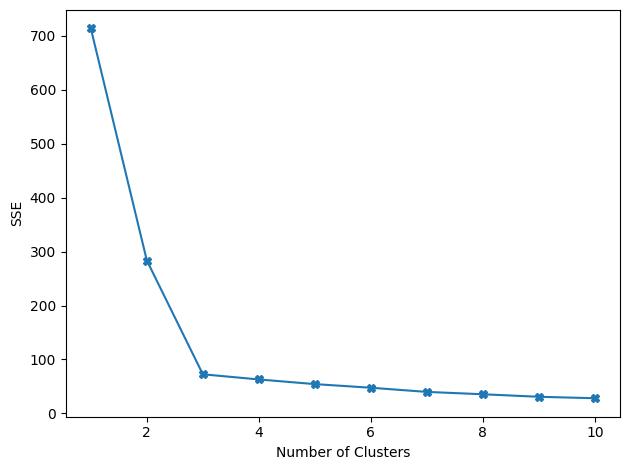

In [15]:
plt.plot(range(1,11) , distortions , marker = 'X')
plt.xlabel('Number of Clusters')
plt.ylabel('SSE')
plt.tight_layout()
plt.show()

### Quantifying the quality of clustering via silhouette plots

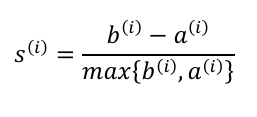

-  the silhouette coefficient is 0 if the cluster separation and cohesion are equal (b(i) = a(i))

- we get close to an ideal silhouette coefficient of 1 if b(i) >> a(i), since b(i) quantifies how dissimilar an 
    example is from other clusters, and a(i) tells us how similar it is to the other examples in its own cluster.


 - as you can see in the preceding silhouette plot, the silhouette coefficients are not close to 0 
    and are approximately equally far away from the average silhouette score, which is, in this case, an 
    indicator of good clustering. 

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


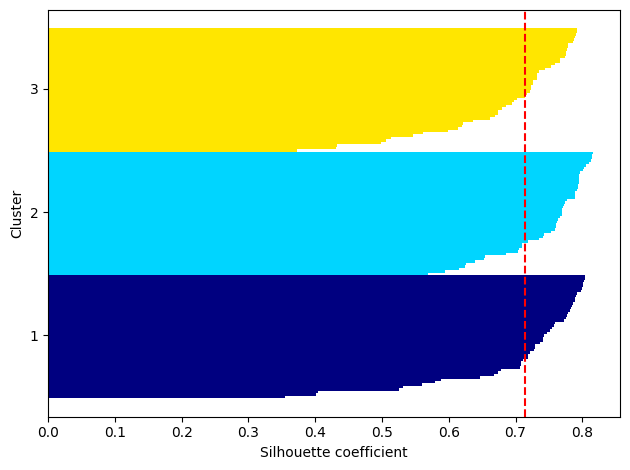

In [16]:
km = KMeans(n_clusters=3,
             init='k-means++',
             n_init=10,
             max_iter=300,
             tol=1e-04,
             random_state=0)
y_km = km.fit_predict(X)
import numpy as np
from matplotlib import cm
from sklearn.metrics import silhouette_samples
cluster_labels = np.unique(y_km)
n_clusters = cluster_labels.shape[0]
silhouette_vals = silhouette_samples(

     X, y_km, metric='euclidean'
  )
y_ax_lower, y_ax_upper = 0, 0
yticks = []
for i, c in enumerate(cluster_labels):
 
     c_silhouette_vals = silhouette_vals[y_km == c]

     c_silhouette_vals.sort()
     y_ax_upper += len(c_silhouette_vals)
     color = cm.jet(float(i) / n_clusters)
     plt.barh(range(y_ax_lower, y_ax_upper),
              c_silhouette_vals,
              height=1.0,
              edgecolor='none',
              color=color)
     yticks.append((y_ax_lower + y_ax_upper) / 2.)
     y_ax_lower += len(c_silhouette_vals)


silhouette_avg = np.mean(silhouette_vals)
plt.axvline(silhouette_avg,
             color="red",
             linestyle="--")
plt.yticks(yticks, cluster_labels + 1)
plt.ylabel('Cluster')
plt.xlabel('Silhouette coefficient')
plt.tight_layout()
plt.show()

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


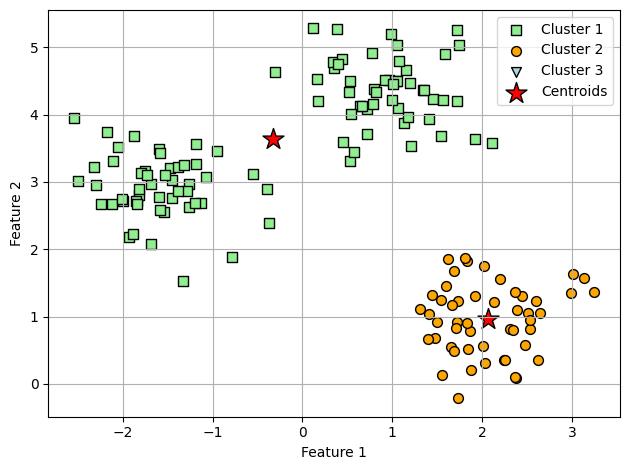

In [17]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2 , init='k-means++' , n_init=10, max_iter = 300 , tol=1e-04 , random_state=0)
y_km = km.fit_predict(X)
plt.scatter(X[y_km == 0, 0],
              X[y_km == 0, 1],
              s=50, c='lightgreen',
             marker='s', edgecolor='black',
             label='Cluster 1')
plt.scatter(X[y_km == 1, 0],
              X[y_km == 1, 1],
              s=50, c='orange',
              marker='o', edgecolor='black',
              label='Cluster 2')
plt.scatter(X[y_km == 2, 0],
              X[y_km == 2, 1],
              s=50, c='lightblue',
              marker='v', edgecolor='black',
              label='Cluster 3')
plt.scatter(km.cluster_centers_[:, 0],
              km.cluster_centers_[:, 1],
             s=250, marker='*',
              c='red', edgecolor='black',
              label='Centroids')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(scatterpoints=1)
plt.grid()
plt.tight_layout()
plt.show()

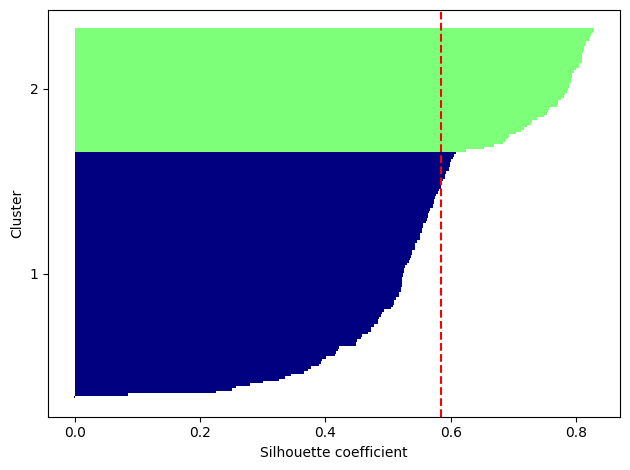

In [18]:
import numpy as np
from matplotlib import cm
from sklearn.metrics import silhouette_samples
cluster_labels = np.unique(y_km)
n_clusters = cluster_labels.shape[0]
silhouette_vals = silhouette_samples(

     X, y_km, metric='euclidean'
  )
y_ax_lower, y_ax_upper = 0, 0
yticks = []
for i, c in enumerate(cluster_labels):
 
     c_silhouette_vals = silhouette_vals[y_km == c]

     c_silhouette_vals.sort()
     y_ax_upper += len(c_silhouette_vals)
     color = cm.jet(float(i) / n_clusters)
     plt.barh(range(y_ax_lower, y_ax_upper),
              c_silhouette_vals,
              height=1.0,
              edgecolor='none',
              color=color)
     yticks.append((y_ax_lower + y_ax_upper) / 2.)
     y_ax_lower += len(c_silhouette_vals)


silhouette_avg = np.mean(silhouette_vals)
plt.axvline(silhouette_avg,
             color="red",
             linestyle="--")
plt.yticks(yticks, cluster_labels + 1)
plt.ylabel('Cluster')
plt.xlabel('Silhouette coefficient')
plt.tight_layout()
plt.show()

### Organizing clusters as a hierarchical tree

 -  hierarchical clustering.

 -  Dendograms 

 - No need to specify the amount of clusters 

 -  agglomerative and divisive

#### Agglometric Clustering Approach

- Single Linkage --> Most similar pair 

- Complete Linkage --> Most dissimilar pair 

- Average Linkage 

- Wards Linkage : the two clusters that lead to the minimum increase of the total within-cluster 
    SSE are merged.

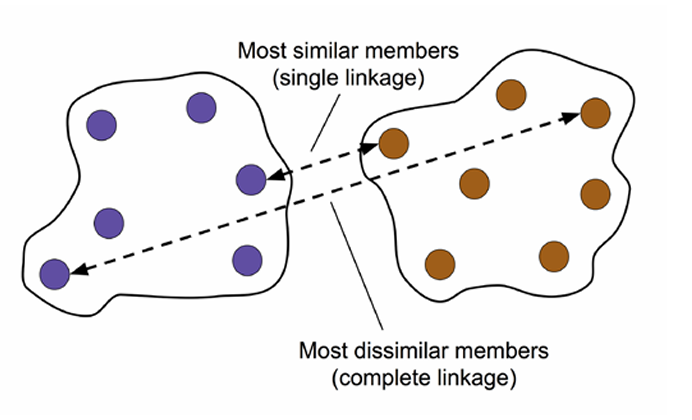

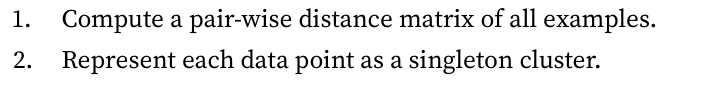
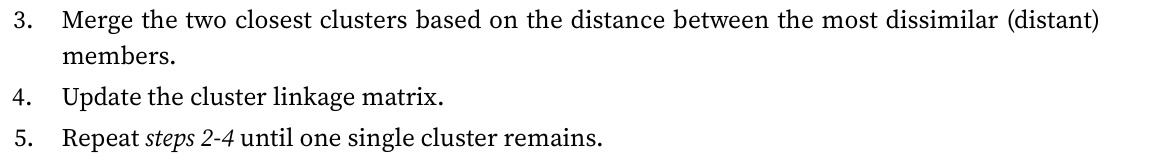

In [19]:
import pandas as pd
import numpy as np
np.random.seed(123)
variables = ['X', 'Y', 'Z']
labels = ['ID_0', 'ID_1', 'ID_2', 'ID_3', 'ID_4']
X = np.random.random_sample([5, 3])*10
df = pd.DataFrame(X, columns=variables, index=labels)
df

,X,Y,Z
ID_0,6.964692,2.861393,2.268515
ID_1,5.513148,7.194690,4.231065
ID_2,9.807642,6.848297,4.809319
ID_3,3.921175,3.431780,7.290497
ID_4,4.385722,0.596779,3.980443


In [20]:
from scipy.spatial.distance import pdist , squareform 

row_dist = pd.DataFrame(squareform(pdist(df , metric = 'euclidean')) , columns=labels , index=labels)
row_dist

,ID_0,ID_1,ID_2,ID_3,ID_4
ID_0,0.000000,4.973534,5.516653,5.899885,3.835396
ID_1,4.973534,0.000000,4.347073,5.104311,6.698233
ID_2,5.516653,4.347073,0.000000,7.244262,8.316594
ID_3,5.899885,5.104311,7.244262,0.000000,4.382864
ID_4,3.835396,6.698233,8.316594,4.382864,0.000000


In [22]:
from scipy.cluster.hierarchy import linkage
help(linkage)

Help on function linkage in module scipy.cluster.hierarchy:

linkage(y, method='single', metric='euclidean', optimal_ordering=False)
    Perform hierarchical/agglomerative clustering.

    The input y may be either a 1-D condensed distance matrix
    or a 2-D array of observation vectors.

    If y is a 1-D condensed distance matrix,
    then y must be a :math:`\binom{n}{2}` sized
    vector, where n is the number of original observations paired
    in the distance matrix. The behavior of this function is very
    similar to the MATLAB linkage function.

    A :math:`(n-1)` by 4 matrix ``Z`` is returned. At the
    :math:`i`-th iteration, clusters with indices ``Z[i, 0]`` and
    ``Z[i, 1]`` are combined to form cluster :math:`n + i`. A
    cluster with an index less than :math:`n` corresponds to one of
    the :math:`n` original observations. The distance between
    clusters ``Z[i, 0]`` and ``Z[i, 1]`` is given by ``Z[i, 2]``. The
    fourth value ``Z[i, 3]`` represents the number of

In [23]:
row_clusters = linkage(pdist(df, metric='euclidean'),
                       method='complete')

In [24]:
pd.DataFrame(row_clusters,
              columns=['row label 1',
                      'row label 2',
                       'distance',
                     'no. of items in clust.'],
            index=[f'cluster {(i + 1)}' for i in
                   range(row_clusters.shape[0])])

,row label 1,row label 2,distance,no. of items in clust.
cluster 1,0.0,4.0,3.835396,2.0
cluster 2,1.0,2.0,4.347073,2.0
cluster 3,3.0,5.0,5.899885,3.0
cluster 4,6.0,7.0,8.316594,5.0


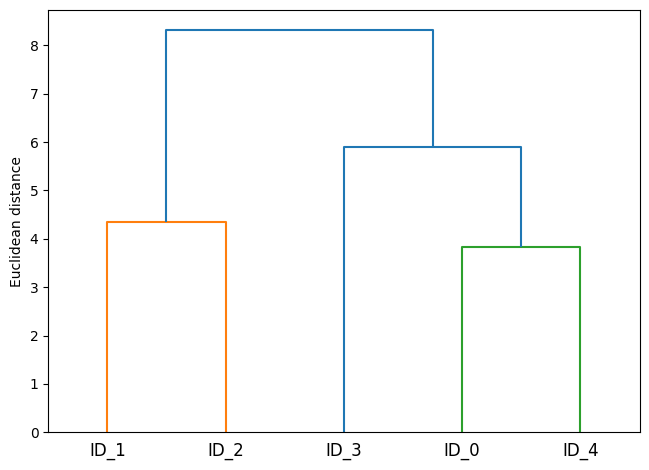

In [35]:
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt 
  # make dendrogram black (part 1/2)
  # from scipy.cluster.hierarchy import set_link_color_palette
  # set_link_color_palette(['black'])
row_dendr = dendrogram(

     row_clusters,     
     labels=labels,
  )
plt.tight_layout()
plt.ylabel('Euclidean distance')
plt.show()

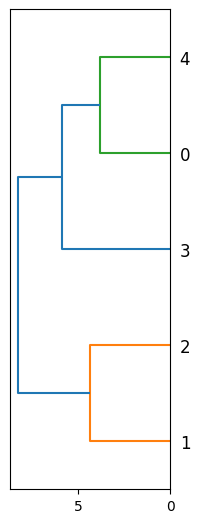

In [36]:
fig = plt.figure(figsize=(8, 8), facecolor='white')
axd = fig.add_axes([0.09, 0.1, 0.2, 0.6])
row_dendr = dendrogram(row_clusters,
                       orientation='left')

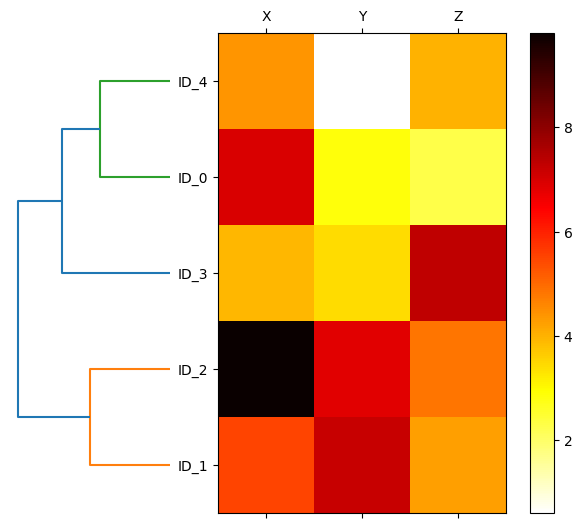

In [47]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import pandas as pd
import numpy as np

# Create figure
fig = plt.figure(figsize=(8, 8), facecolor='white')

# Create dendrogram axes (left side)
axd = fig.add_axes([0.09, 0.1, 0.2, 0.6])
row_dendr = dendrogram(row_clusters, orientation='left')

# Reorder dataframe based on dendrogram
df_rowclust = df.iloc[row_dendr['leaves'][::-1]]

# Create heatmap axes (main area)
axm = fig.add_axes([0.23, 0.1, 0.6, 0.6])
cax = axm.matshow(df_rowclust,
                  interpolation='nearest',
                  cmap='hot_r')

# Clean up dendrogram axes
axd.set_xticks([])
axd.set_yticks([])
for i in axd.spines.values():
    i.set_visible(False)

# Add colorbar
fig.colorbar(cax, ax=axm)

# Set labels for heatmap
axm.set_xticks(range(len(df_rowclust.columns)))
axm.set_yticks(range(len(df_rowclust.index)))
axm.set_xticklabels(list(df_rowclust.columns))
axm.set_yticklabels(list(df_rowclust.index))

plt.show()

###  Applying agglomerative clustering via scikit-learn

In [49]:
from sklearn.cluster import AgglomerativeClustering
ac = AgglomerativeClustering(n_clusters=3,
                               metric='euclidean',
                              linkage='complete')

labels = ac.fit_predict(X)
print(f'Cluster labels: {labels}')

Cluster labels: [1 0 0 2 1]


In [50]:
ac = AgglomerativeClustering(n_clusters=2,
                              metric='euclidean',
                              linkage='complete')
labels = ac.fit_predict(X)
print(f'Cluster labels: {labels}')

Cluster labels: [0 1 1 0 0]


###  Locating regions of high density via DBSCAN

- A point is considered a core point if at least a specified number (MinPts) of neighboring points 
    fall within the specified radius, 𝜀𝜀 

- A border point is a point that has fewer neighbors than MinPts within 𝜀𝜀 , but lies within the 𝜀𝜀  
    radius of a core poin

- else Nosie Points 

- Capable of removing Noise 

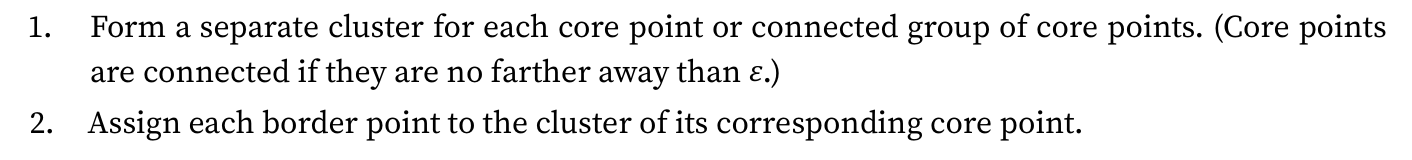

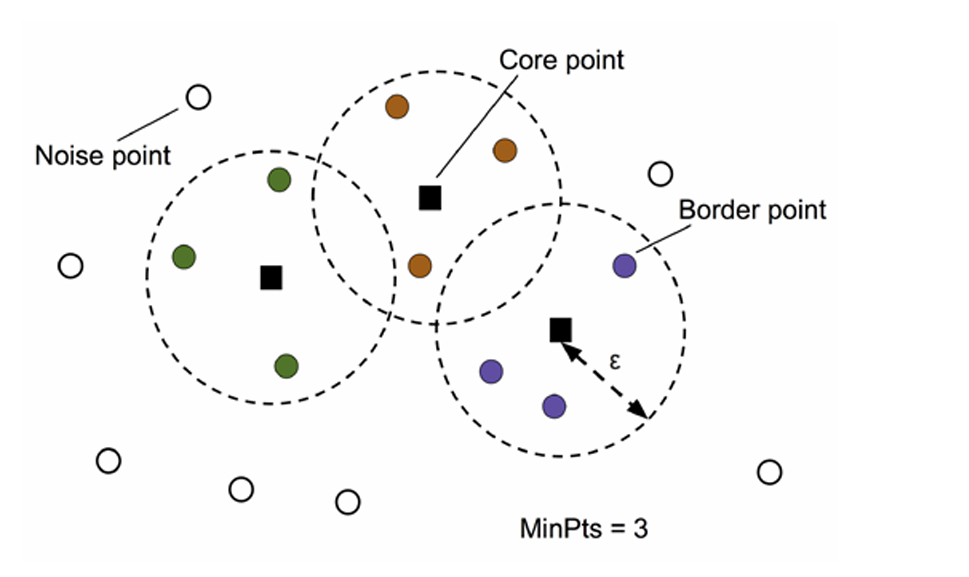

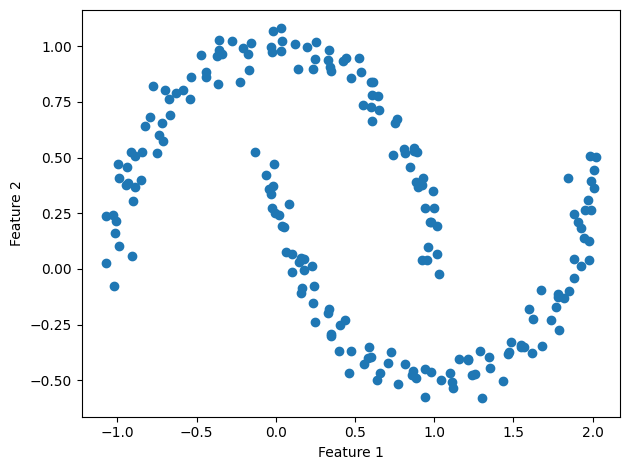

In [54]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples= 200, 
                  noise= 0.05 , 
                  random_state=0)
plt.scatter(X[:,0],X[:,1])
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.tight_layout()
plt.show()

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


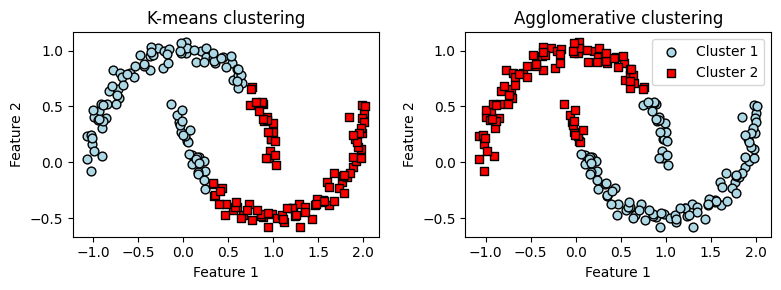

In [57]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

km = KMeans(n_clusters=2, random_state=0)
y_km = km.fit_predict(X)

ax1.scatter(X[y_km == 0, 0], 
           X[y_km == 0, 1], 
           c='lightblue', 
           edgecolor='black', 
           marker='o', 
           s=40, 
           label='cluster 1')

ax1.scatter(X[y_km == 1, 0], 
           X[y_km == 1, 1], 
           c='red', 
           edgecolor='black', 
           marker='s', 
           s=40, 
           label='cluster 2')

ax1.set_title('K-means clustering')
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Feature 2')

ac = AgglomerativeClustering(n_clusters=2, 
                           metric='euclidean', 
                           linkage='complete')
y_ac = ac.fit_predict(X)

ax2.scatter(X[y_ac == 0, 0], 
           X[y_ac == 0, 1], 
           c='lightblue', 
           edgecolor='black', 
           marker='o', 
           s=40, 
           label='Cluster 1')

ax2.scatter(X[y_ac == 1, 0], 
           X[y_ac == 1, 1], 
           c='red', 
           edgecolor='black', 
           marker='s', 
           s=40, 
           label='Cluster 2')

ax2.set_title('Agglomerative clustering')
ax2.set_xlabel('Feature 1')
ax2.set_ylabel('Feature 2')

plt.legend()
plt.tight_layout()
plt.show()

- we should also note some of the disadvantages of DBSCAN. With an increasing number of 
    features in our dataset—assuming a fixed number of training examples—the negative effect of the 
    curse of dimensionality increases. 

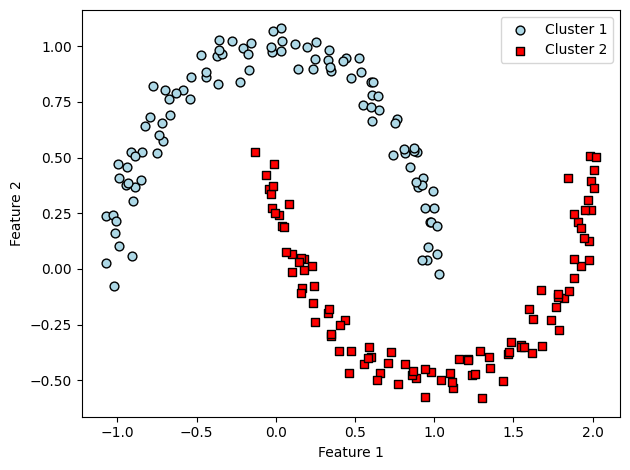

In [58]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.2, 
           min_samples=5, 
           metric='euclidean')
y_db = db.fit_predict(X)

plt.scatter(X[y_db == 0, 0], 
           X[y_db == 0, 1], 
           c='lightblue', 
           edgecolor='black', 
           marker='o', 
           s=40, 
           label='Cluster 1')

plt.scatter(X[y_db == 1, 0], 
           X[y_db == 1, 1], 
           c='red', 
           edgecolor='black', 
           marker='s', 
           s=40, 
           label='Cluster 2')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.tight_layout()
plt.show()

### Graph based Clustering 